In [1]:
import pandas as pd
import numpy as np 

In [4]:
df = pd.read_csv("C:\\Users\\yasht\\Desktop\\AI_ML\\FUTURE_ML_01\\data\\raw\\train.csv")

In [5]:
df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [7]:
df["lag_1"] = df.groupby(["store","item"])["sales"].shift(1)
df["lag_7"] = df.groupby(["store","item"])["sales"].shift(7)

In [9]:
df[["store","item","sales","lag_1","lag_7"]].head(10)

,store,item,sales,lag_1,lag_7
0,1,1,13,NaN,NaN
1,1,1,11,13.0,NaN
2,1,1,14,11.0,NaN
3,1,1,13,14.0,NaN
4,1,1,10,13.0,NaN
5,1,1,12,10.0,NaN
6,1,1,10,12.0,NaN
7,1,1,9,10.0,13.0
8,1,1,12,9.0,11.0
9,1,1,9,12.0,14.0


In [12]:
df["rolling_mean_7"] = df.groupby(["store","item"])["sales"].transform(lambda x: x.shift(1).rolling(window=7).mean())

In [14]:
df[["date","store","item","sales","lag_1","lag_7","rolling_mean_7"]].head(15)


,date,store,item,sales,lag_1,lag_7,rolling_mean_7
0,2013-01-01,1,1,13,NaN,NaN,NaN
1,2013-01-02,1,1,11,13.0,NaN,NaN
2,2013-01-03,1,1,14,11.0,NaN,NaN
3,2013-01-04,1,1,13,14.0,NaN,NaN
4,2013-01-05,1,1,10,13.0,NaN,NaN
5,2013-01-06,1,1,12,10.0,NaN,NaN
6,2013-01-07,1,1,10,12.0,NaN,NaN
7,2013-01-08,1,1,9,10.0,13.0,11.857143
8,2013-01-09,1,1,12,9.0,11.0,11.285714
9,2013-01-10,1,1,9,12.0,14.0,11.428571


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   date            913000 non-null  str    
 1   store           913000 non-null  int64  
 2   item            913000 non-null  int64  
 3   sales           913000 non-null  int64  
 4   lag_1           912500 non-null  float64
 5   lag_7           909500 non-null  float64
 6   rolling_mean_7  909500 non-null  float64
dtypes: float64(3), int64(3), str(1)
memory usage: 48.8 MB


In [16]:
df['date'] = pd.to_datetime(df['date'])

In [18]:
df.isnull().sum()

date                 0
store                0
item                 0
sales                0
lag_1              500
lag_7             3500
rolling_mean_7    3500
dtype: int64

In [19]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek
df["is_weekend"] = df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

In [20]:
df.head()

,date,store,item,sales,lag_1,lag_7,rolling_mean_7,year,month,day,day_of_week,is_weekend
0,2013-01-01,1,1,13,NaN,NaN,NaN,2013,1,1,1,0
1,2013-01-02,1,1,11,13.0,NaN,NaN,2013,1,2,2,0
2,2013-01-03,1,1,14,11.0,NaN,NaN,2013,1,3,3,0
3,2013-01-04,1,1,13,14.0,NaN,NaN,2013,1,4,4,0
4,2013-01-05,1,1,10,13.0,NaN,NaN,2013,1,5,5,1


In [22]:
df = df.dropna(subset = ["lag_1", "lag_7", "rolling_mean_7"])
df[["lag_1", "lag_7", "rolling_mean_7"]].isnull().sum()

lag_1             0
lag_7             0
rolling_mean_7    0
dtype: int64

In [ ]:
df.isnull().sum()

date              0
store             0
item              0
sales             0
lag_1             0
lag_7             0
rolling_mean_7    0
year              0
month             0
day               0
day_of_week       0
is_weekend        0
dtype: int64

In [24]:
features = ["store", "item", "lag_1", "lag_7", "rolling_mean_7", "year", "month", "day", "day_of_week", "is_weekend"]
X = df[features]
y = df["sales"]

In [25]:
split_index = int(len(df)*0.8)

X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

In [30]:
from sklearn.linear_model import LinearRegression

In [31]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[-0. , 0. , 0.02,...,-0.01, 2.69, 0.25]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['store','item','lag_1',...,'day','day_of_week','is_weekend']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-60.79
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [32]:
y_pred = model.predict(X_test)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 6.19677635290575
RMSE: 7.992551830908601
R² Score: 0.9006784952123724


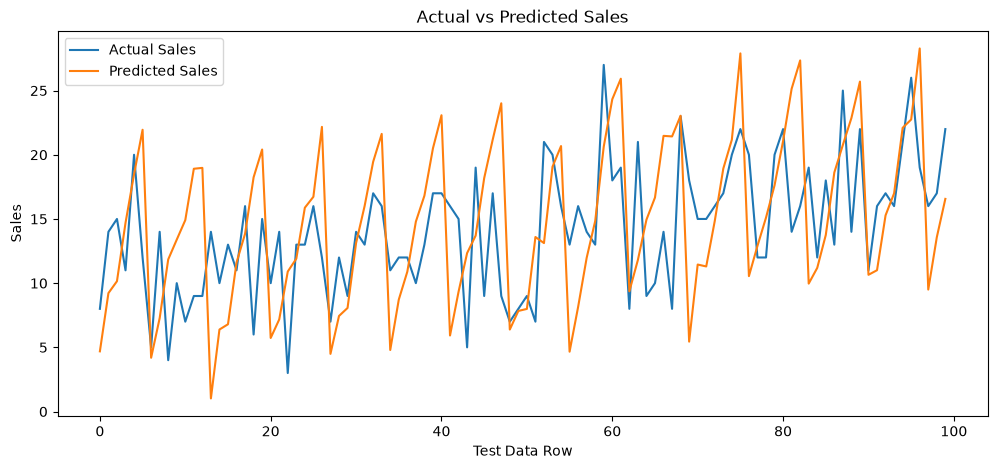

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.iloc[:100].values,
    label="Actual Sales"
)

plt.plot(
    y_pred[:100],
    label="Predicted Sales"
)

plt.xlabel("Test Data Row")
plt.ylabel("Sales")
plt.title("Actual vs Predicted Sales")
plt.legend()
plt.show()

In [36]:
from sklearn.ensemble import RandomForestRegressor

print("Random Forest import successful")

Random Forest import successful


In [38]:
RF_model = RandomForestRegressor(n_estimators=100, random_state=42,n_jobs=-1)


In [39]:
RF_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [42]:
rf_pred = RF_model.predict(X_test)


mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 5.747259428257284
RMSE: 7.466785264735062
R² Score: 0.9133158506604451


In [43]:
comparison_rf = pd.DataFrame({
    "Actual Sales": y_test.iloc[:20].values,
    "Predicted Sales": rf_pred[:20]
})

comparison_rf

,Actual Sales,Predicted Sales
0,8,10.82
1,14,11.42
2,15,9.00
3,11,13.60
4,20,13.79
5,12,15.10
6,5,10.82
7,14,12.54
8,4,15.23
9,10,13.90


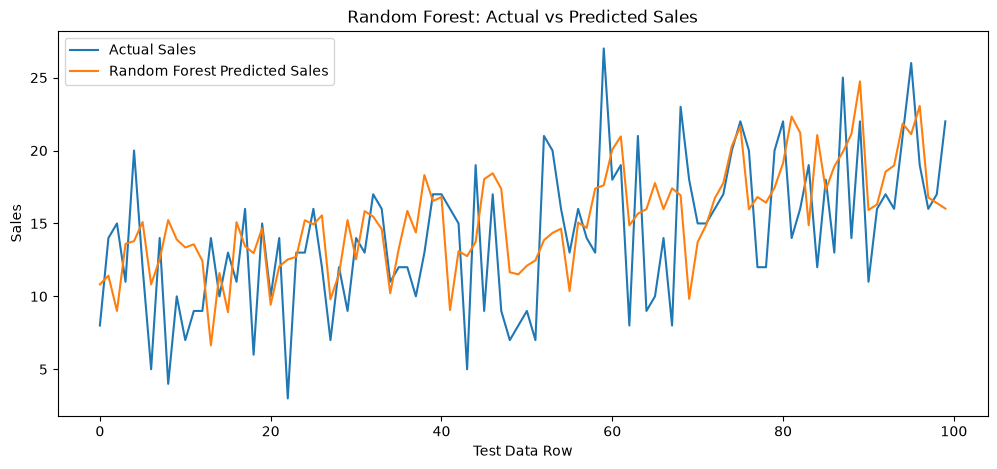

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.iloc[:100].values,
    label="Actual Sales"
)

plt.plot(
    rf_pred[:100],
    label="Random Forest Predicted Sales"
)

plt.xlabel("Test Data Row")
plt.ylabel("Sales")
plt.title("Random Forest: Actual vs Predicted Sales")
plt.legend()
plt.show()

##* feature importance -----

In [45]:
feature_importance = pd.Series(
    RF_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

feature_importance

lag_7             0.719279
rolling_mean_7    0.182566
lag_1             0.027948
day_of_week       0.022952
day               0.013086
item              0.010686
month             0.009919
store             0.007371
year              0.005072
is_weekend        0.001121
dtype: float64

In [47]:
import joblib

joblib.dump(RF_model, "../models/sales_forecasting_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [48]:
from sklearn.ensemble import RandomForestRegressor

rf_model_small = RandomForestRegressor(
    n_estimators=30,
    random_state=42,
    n_jobs=2,
    max_depth=20
)

rf_model_small.fit(X_train, y_train)

print("Memory-friendly Random Forest trained successfully!")

Memory-friendly Random Forest trained successfully!


In [49]:
y_pred_small = rf_model_small.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred_small))
print("RMSE:", mean_squared_error(y_test, y_pred_small) ** 0.5)
print("R2:", r2_score(y_test, y_pred_small))

MAE: 5.751787124375993
RMSE: 7.482181561830235
R2: 0.9129580016429228


In [50]:
import joblib
from pathlib import Path

model_path = Path("../models/sales_forecasting_model.pkl")

joblib.dump(rf_model_small, model_path)

print("Model saved successfully!")
print(f"Model size: {model_path.stat().st_size / (1024**2):.2f} MB")

Model saved successfully!
Model size: 598.53 MB
